Using device: cuda
(3150, 4)


Epoch 100/1000: 100%|██████████| 35/35 [00:00<00:00, 101.97it/s]


Epoch 100/1000
  Train Loss: 16.0941 (Main: 1.9796, Constraint: 10.0881, Time: 0.0071)
  Val Loss: 20.3467 (Main: 2.1165, Constraint: 13.9277, Time: 0.0016)


Epoch 200/1000: 100%|██████████| 35/35 [00:00<00:00, 41.23it/s]


Epoch 200/1000
  Train Loss: 7.0292 (Main: 1.8315, Constraint: 1.5253, Time: 0.0016)
  Val Loss: 7.2228 (Main: 1.9202, Constraint: 1.4538, Time: 0.0016)


Epoch 300/1000: 100%|██████████| 35/35 [00:00<00:00, 123.30it/s]


... (11 outputs left out)

Epoch 900/1000: 100%|██████████| 35/35 [00:00<00:00, 125.10it/s]


Epoch 900/1000
  Train Loss: 6.7871 (Main: 1.8094, Constraint: 1.3521, Time: 0.0016)
  Val Loss: 7.1415 (Main: 1.9090, Constraint: 1.4083, Time: 0.0016)


Epoch 1000/1000: 100%|██████████| 35/35 [00:00<00:00, 132.34it/s]


Epoch 1000/1000
  Train Loss: 6.7975 (Main: 1.8130, Constraint: 1.3517, Time: 0.0016)
  Val Loss: 7.1406 (Main: 1.9089, Constraint: 1.4074, Time: 0.0016)


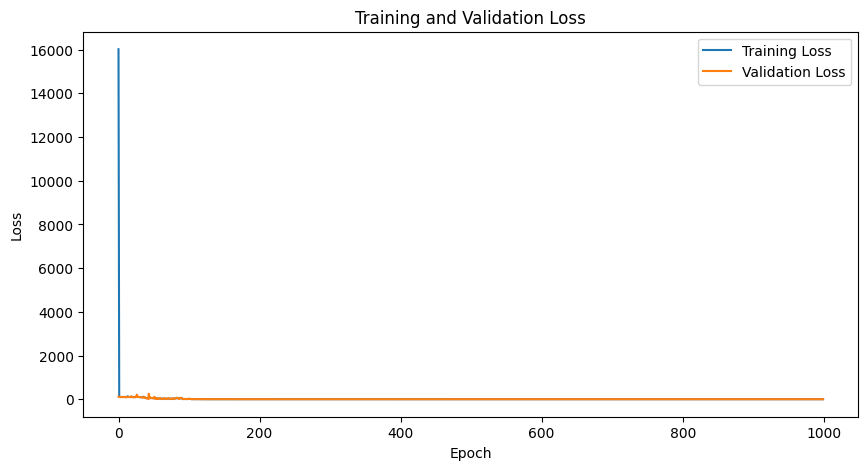

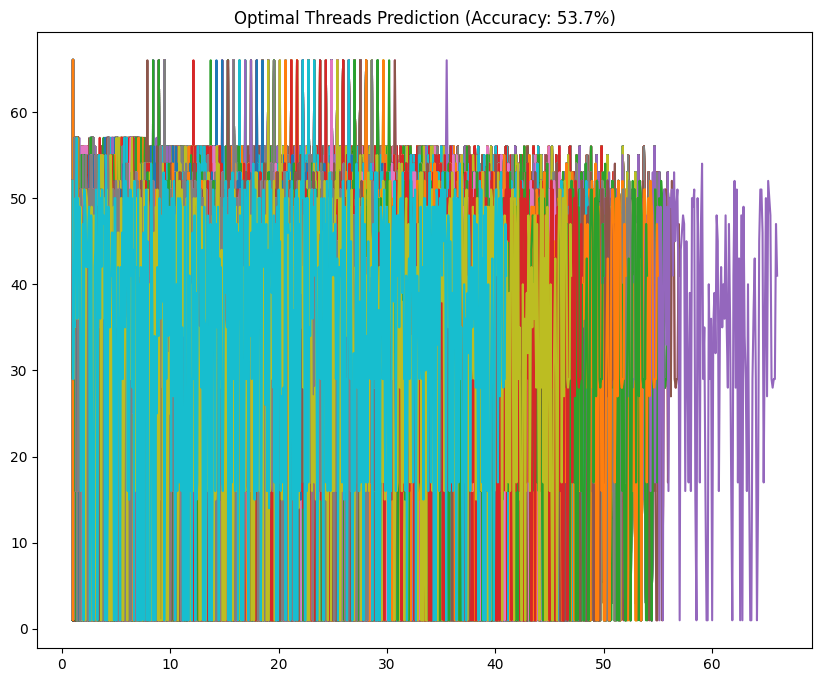

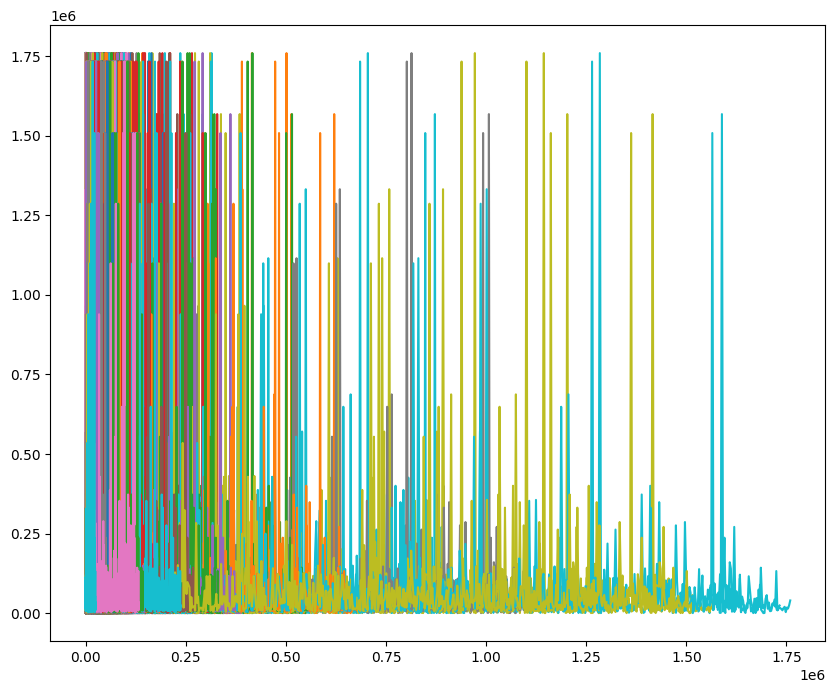

Prediction Accuracy (±1 thread): 53.65%
Mean Absolute Error: 1.829 threads
Mean Relative Error: 10.49%
Standard Deviation: 0.1537


In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import joblib
from torch.utils.data import Dataset, DataLoader
# import matplotlib
# matplotlib.use('TkAgg')
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
# 设置随机种子确保可重复性
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# 硬件特征参数
HARDWARE_FEATURES = [
    "usr",
    "system",
    "VSZ",
    "cswch"
]


# 模拟数据生成器
class ParallelSimulationDataset(Dataset):
    def __init__(self, test_mode=False):
        self.data = self.generate_data()

        # 特征和标签分离
        self.features_static = self.data[["N", "mu_e", "thread"]].values
        self.features_runinf = self.data[['usr', 'system', 'VSZ', 'cswch']].values
        # self.features_runinf = self.data[['usr', 'system', 'cswch']].values
        self.labels_k = self.data["k_opt"].values.reshape(-1, 1)
        self.labels_t = self.data["time"].values.reshape(-1, 1)

        self.feature_scaler = StandardScaler()
        self.feature_scaler.fit(self.features_runinf)
        # joblib.dump(self.feature_scaler, 'feature_scaler.pkl')

        if not test_mode:
            self.features_runinf = self.feature_scaler.transform(self.features_runinf)
        self.features = np.concatenate((self.features_static, self.features_runinf), axis=1)

    def generate_data(self):
        input_path = "E:\paper\论文\论文2-机器学习线程与预测\dataset\整体\Allog_Airline_AMD.xlsx"
        # input_path = "E:\paper\论文\论文2-机器学习线程与预测\dataset\整体\Allog_PCS_X86.xlsx"
        data = pd.read_excel(input_path, engine='openpyxl', sheet_name='runinf')
        N = np.array(data.loc[:, 'taskque'])
        k = np.array(data.loc[:, 'thread'])
        mu_e = 1 / np.array(data.loc[:, 'mean_excute2_time'])
        # mu_e = np.array(data.loc[:, 'complex'])
        h = np.array(data.loc[:, ['sum_usr', 'sum_system', 'VSZ', 'mean_cswch']]) #硬件信息
        print(h.shape)
        T = np.array(data.loc[:, 'mean_excute_time']) #真实运行时间
        best_k = np.array(data.loc[:, 'optimal_thread']) #真实最优线程数

        # 添加到数据
        sample = {
                "N": N,
                "mu_e": mu_e,
                "k_opt": best_k,
                "thread": k,
                "time": T,
                "usr": h[:,0],
                "system": h[:,1],
                "VSZ": h[:,2],
                "cswch": h[:,3],
        }
        return pd.DataFrame(sample)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        features = self.features[idx]
        label_kopt = self.labels_k[idx]
        label_time = self.labels_t[idx]

        return torch.tensor(features, dtype=torch.float32), torch.tensor(label_kopt, dtype=torch.int), torch.tensor(label_time, dtype=torch.float32)


# 物理计算模块
def calc_mu_b(k_transfor, k, a1, b1, a2, b2):
    """计算任何k下的μ_b(k)"""
    # 使用sigmoid平滑过渡
    sig_weight = torch.sigmoid(10 * (k_transfor.detach() - k))
    return sig_weight * (a1 * k + b1) + (1 - sig_weight) * (a2 * k + b2)

def calc_exec_time(N, k, mu_e, mu_b):
    """计算执行时间，考虑临界区行为"""
    ceil_val = torch.ceil(N / k)
    cond = (mu_b > k * mu_e).float()

    t_case1 = ceil_val / mu_e + N / (mu_b - k * mu_e + 1e-8)
    t_case2 = N / mu_b + 1 / mu_e

    return cond * t_case1 + (1 - cond) * t_case2


# 核心预测模型
class CrossAttention(nn.Module):
    def __init__(self, d_q, d_k, d_v, d_out):
        super().__init__()
        self.w_q = nn.Linear(d_q, d_out, bias=False)
        self.w_k = nn.Linear(d_k, d_out, bias=False)
        self.w_v = nn.Linear(d_v, d_out, bias=False)
        self.scale = d_k ** -0.5

    def forward(self, query, key, value):
        # query/key/value: (B, L, d_model)
        q = self.w_q(query)                        # (B, L, d_k)
        k = self.w_k(key)                          # (B, L, d_k)
        v = self.w_v(value)                        # (B, L, d_k)
        attn = torch.softmax(q @ k.transpose(-2, -1) * self.scale, dim=-1)
        out = attn @ v                             # (B, L, d_k)
        return out
    
class OptimalThreadsPredictor(nn.Module):
    def __init__(self,
                 input_dim,
                 hw_dim=len(HARDWARE_FEATURES),
                 hidden_dim=128,
                 d_attn=64):
        super().__init__()
        self.hw_dim = hw_dim

        # 1) 硬件编码器
        self.hw_encoder = nn.Sequential(
            nn.Linear(hw_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU()
        )

        # 2) 参数编码器（N, mu_e_noisy, thread）
        self.param_encoder = nn.Sequential(
            nn.Linear(3, 32),
            nn.LayerNorm(32),
            nn.ReLU(),
            nn.Linear(32, d_attn),
            nn.LayerNorm(d_attn),
            nn.ReLU()
        )

        # 3) 交叉注意力：hw_feat (Q) x param_feat (K,V)
        self.cross_attn = CrossAttention(
            d_q=hidden_dim,      # hw_feat 的维度
            d_k=d_attn,          # param_feat 的维度
            d_v=d_attn,          # param_feat 的维度
            d_out=d_attn         # 输出维度
        )

        # 4) 共享 backbone
        self.backbone = nn.Sequential(
            nn.Linear(hidden_dim + d_attn, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU()
        )

        # 5) 多输出头（共享 backbone）
        self.head_k_opt = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
        self.head_a1 = nn.Linear(hidden_dim, 1)
        self.head_b1 = nn.Linear(hidden_dim, 1)
        self.head_a2 = nn.Linear(hidden_dim, 1)
        self.head_b2 = nn.Linear(hidden_dim, 1)
        self.head_time = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        """
        x: (B, INPUT_DIM)
           0:N, 1:mu_e_noisy, 2:thread, 3...:hw_features
        mu_e_true: (B,1) 无噪声真值，用于物理计算
        """
        N       = x[:, 0:1]
        mu_e  = x[:, 1:2]          # 观测（带噪）
        thread  = x[:, 2:3]
        hw      = x[:, 3:3 + self.hw_dim]

        # 编码
        hw_feat   = self.hw_encoder(hw)              # (B, hidden)
        param_feat= self.param_encoder(torch.cat([N, mu_e, thread], dim=1))  # (B, d_attn)

        # 交叉注意力融合
        hw_feat = hw_feat.unsqueeze(1)               # (B,1,hidden) -> Q
        param_feat = param_feat.unsqueeze(1)         # (B,1,d_attn) -> K,V
        fused = self.cross_attn(hw_feat, param_feat, param_feat)  # (B,1,d_attn)
        fused = fused.squeeze(1)                     # (B,d_attn)
        fused = torch.cat([hw_feat.squeeze(1), fused], dim=1)     # (B, hidden+d_attn)

        shared = self.backbone(fused)                # (B, hidden)

        # 多输出头
        k_raw   = self.head_k_opt(shared)
        k_opt   = torch.exp(k_raw) + 1.0             # 保证 >1，梯度友好
        a1      = self.head_a1(shared)
        b1      = self.head_b1(shared)
        a2      = self.head_a2(shared)
        b2      = self.head_b2(shared)
        time_pred = self.head_time(shared)

        # 物理量计算（使用无噪声 mu_e_true，若未提供用观测值）
        mu_b_at_kopt = a1 * k_opt + b1
        k_opt_phys = mu_b_at_kopt / (2*mu_e)
        # k_opt_phys =torch.nan_to_num(k_opt_phys, nan=64.0, posinf=64.0, neginf=1)
        k_transfor = mu_b_at_kopt / mu_e
        # k_transfor = torch.nan_to_num(k_transfor, nan=64.0, posinf=64.0, neginf=1)
        mu_b_at_thread = calc_mu_b(k_transfor, thread, a1, b1, a2, b2)
        time_at_thread = calc_exec_time(N, thread, mu_e, mu_b_at_thread)
    
        return {
            "k_opt": k_opt,
            "k_opt_phys": k_opt_phys,
            "k_transfor": k_transfor,
            "a1": a1,
            "b1": b1,
            "a2": a2,
            "b2": b2,
            "mu_b_at_kopt": mu_b_at_kopt,
            "time_at_thread": time_at_thread,
            "mu_b_at_thread": mu_b_at_thread
        }

# 自定义损失函数
class OptimalThreadsLoss(nn.Module):
    def __init__(self, alpha=2.0, beta=0.5, gama=1.0, rba_decay=0.9, rba_scale=10.0):
        super().__init__()
        self.alpha = alpha  # 主要k_opt损失权重
        self.beta = beta  # 物理约束权重
        self.gama = gama
        self.rba_decay = rba_decay
        self.rba_scale = rba_scale
        # 初始化残差移动平均变量
        self.register_buffer('residual_ema', torch.tensor(0.0))
        self.register_buffer('weight_scale', torch.tensor(1.0))

    def compute_residuals(self, k_opt_pred, k_opt_phys, mu_b_left, mu_b_right):
        """
        计算物理约束残差
        """
        phys_residual = torch.abs(k_opt_pred - k_opt_phys) # 1. 物理约束残差 |k_opt_pred - k_opt_phys|
        continuity_residual = torch.abs(mu_b_left - mu_b_right)  # 2. 连续性残差 |(a1*k + b1) - (a2*k + b2)|
        residual = phys_residual + 0.5 * continuity_residual  # 3. 综合残差 (可以根据需要调整加权)
        return residual

    
    def compute_rba_weights(self, residuals):
        """
        计算基于残差的注意力权重
        """
        # 首次迭代初始化指数移动平均
        batch_size = residuals.size(0)
        if self.residual_ema == 0.0:
            self.residual_ema = torch.tensor(residuals.detach().mean().item(), 
                                                 device=self.residual_ema.device)
        # 计算当前批次的残差均值
        current_mean = torch.tensor(residuals.detach().mean().item(), 
                                   device=self.residual_ema.device)
        # 更新残差指数移动平均
        self.residual_ema.data = (self.rba_decay * self.residual_ema + 
                                 (1 - self.rba_decay) * current_mean)
        # 计算归一化残差 (相对于移动平均)
        norm_res = residuals / (self.residual_ema.item() + 1e-8)
         # 计算原始注意力权重
        raw_weights = torch.sigmoid(self.rba_scale * norm_res)
        # 计算权重缩放因子 (首次迭代跳过)
        if self.weight_scale.item() == 1.0:
            current_scale = raw_weights.detach().mean().item()
            if current_scale > 0:
                self.weight_scale.data = torch.tensor(1.0 / current_scale, 
                                                    device=self.weight_scale.device)
        else:
            current_scale = raw_weights.detach().mean().item()
            if current_scale > 0:
                target_scale = 1.0 / current_scale
                # 更新权重缩放因子 (平滑过渡)
                self.weight_scale.data = torch.tensor(
                    0.9 * self.weight_scale.item() + 0.1 * target_scale, 
                    device=self.weight_scale.device)
                
        weights = raw_weights * self.weight_scale.item()
        return weights.detach()
    
    def forward(self, outputs, k_opt_true, time_true):
        # 主要损失：k_opt预测精度
        k_opt_pred = outputs["k_opt"]
        main_loss = F.l1_loss(k_opt_pred, k_opt_true)

        # 物理约束损失: k_opt_pred ≈ (a1*k_opt_pred + b1)/mu_e
        k_opt_phys = outputs["k_opt_phys"]
        constraint_loss = F.l1_loss(k_opt_pred, k_opt_phys)

        # 物理连续性损失: a1*k_opt + b1 ≈ a2*k_opt + b2
        k_transfer = outputs["k_transfor"].detach()
        mu_b_left = outputs["a1"] * k_transfer + outputs["b1"]
        mu_b_right = outputs["a2"] * k_transfer + outputs["b2"]
        continuity_loss = F.mse_loss(mu_b_left, mu_b_right)

        # 时间约束
        time_loss = F.mse_loss(time_true/1000000.0, outputs["time_at_thread"]/1000000.0)

        residuals = self.compute_residuals(k_opt_pred, k_opt_phys, mu_b_left, mu_b_right)  # 计算物理约束残差
        rba_weights = self.compute_rba_weights(residuals) # 计算RBA注意力权重
        weighted_constraint = torch.mean(rba_weights * (k_opt_pred - k_opt_phys) ** 2) # 应用注意力权重到物理约束损失
        weighted_continuity = torch.mean(rba_weights * (mu_b_left - mu_b_right) ** 2)
        
        # 总损失
        total_loss = (self.alpha * main_loss +
                      self.beta * (constraint_loss + continuity_loss) + self.gama*time_loss)

        return total_loss, {
            "main_loss": main_loss.item(),
            "constraint_loss": constraint_loss.item(),
            "continuity_loss": continuity_loss.item(),
            "time_loss": time_loss.item()
        }


# 训练函数
def train(model, train_loader, val_loader, device, epochs=500, lr=0.01):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = OptimalThreadsLoss(alpha=3, beta=1)

    # 学习率调度器
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=10)

    train_loss_history, val_loss_history = [], []
    best_val_loss = float('inf')

    # 动态调整约束权重
    def update_constraint_weight(epoch):
        # 初期侧重物理约束，后期侧重主损失
        if epoch < 100:
            return 2
        elif epoch < 300:
            return 1
        else:
            return 0.8

    for epoch in range(epochs):
        # 更新约束权重
        criterion.gama = update_constraint_weight(epoch)

        # 训练阶段
        model.train()
        train_loss = 0
        main_loss_avg, constraint_loss_avg, time_loss_avg = 0, 0, 0

        for features, labels_kopt, label_time in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}"):
            features, labels_kopt, label_time = features.to(device), labels_kopt.to(device), label_time.to(device)

            optimizer.zero_grad()
            outputs = model(features)
            loss, loss_components = criterion(outputs, labels_kopt, label_time)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            train_loss += loss.item()
            main_loss_avg += loss_components["main_loss"]
            constraint_loss_avg += loss_components["constraint_loss"]
            time_loss_avg += loss_components["time_loss"]

        # 验证阶段
        model.eval()
        val_loss = 0
        val_main_loss, val_constraint_loss, val_time_loss = 0, 0, 0

        with torch.no_grad():
            for features, labels_kopt, label_time in val_loader:
                features, labels_kopt, label_time = features.to(device), labels_kopt.to(device), label_time.to(device)
                outputs = model(features)
                loss, loss_components = criterion(outputs, labels_kopt, label_time)

                val_loss += loss.item()
                val_main_loss += loss_components["main_loss"]
                val_constraint_loss += loss_components["constraint_loss"]
                val_time_loss += loss_components["time_loss"]

        # 计算平均损失
        train_loss /= len(train_loader)
        main_loss_avg /= len(train_loader)
        constraint_loss_avg /= len(train_loader)
        time_loss_avg /= len(train_loader)

        val_loss /= len(val_loader)
        val_main_loss /= len(val_loader)
        val_constraint_loss /= len(val_loader)
        val_time_loss /= len(val_loader)

        # 记录历史
        train_loss_history.append(train_loss)
        val_loss_history.append(val_loss)

        # 更新学习率
        scheduler.step(val_loss)

        # 保存最佳模型
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), "best_model.pth")
            # with open('best_model.pth', 'wb') as f:
            #     pickle.dump(model, f)

        # 打印训练进度
        if (epoch + 1) % 100 == 0:
            print(f"Epoch {epoch + 1}/{epochs}")
            print(f"  Train Loss: {train_loss:.4f} (Main: {main_loss_avg:.4f}, Constraint: {constraint_loss_avg:.4f}, Time: {time_loss_avg:.4f})")
            print(f"  Val Loss: {val_loss:.4f} (Main: {val_main_loss:.4f}, Constraint: {val_constraint_loss:.4f}, Time: {val_time_loss:.4f})")

    # 绘制损失曲线
    plt.figure(figsize=(10, 5))
    plt.plot(train_loss_history, label='Training Loss')
    plt.plot(val_loss_history, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.show()

    # 加载最佳模型
    model.load_state_dict(torch.load("best_model.pth"))
    # with open('best_model.pth', 'wb') as f:
    #     model1 = pickle.load(model, f)
    return model


# 评估函数
def evaluate(model, test_loader, device):
    model.eval()
    model.to(device)

    k_opt_preds, k_opt_trues, k_phy_preds, time_preds, time_trues = [], [], [], [], []
    relative_errors = []

    with torch.no_grad():
        for features, labels_kopt, label_time in test_loader:
            features, labels_kopt, label_time = features.to(device), labels_kopt.to(device), label_time.to(device)
            outputs = model(features)

            k_opt_pred = outputs["k_opt"].cpu().numpy()
            k_phy_pred = outputs["k_opt_phys"].cpu().numpy()
            time_pred = outputs["time_at_thread"].cpu().numpy()
            k_opt_true = labels_kopt.cpu().numpy()
            time_true = label_time.cpu().numpy()

            k_opt_preds.extend(k_opt_pred.flatten())
            k_opt_trues.extend(k_opt_true.flatten())
            k_phy_preds.extend(k_phy_pred.flatten())
            time_preds.extend(time_pred.flatten())
            time_trues.extend(time_true.flatten())

            # 计算相对误差
            errors = np.abs(k_opt_pred.flatten() - k_opt_true.flatten()) / k_opt_true.flatten()
            relative_errors.extend(errors)

    # 将预测值和真实值转换为整数线程数
    k_opt_preds = np.round(k_opt_preds).astype(int)
    k_opt_trues = np.round(k_opt_trues).astype(int)
    k_phy_preds = np.round(k_phy_preds).astype(int)

    # 计算准确率（差值在1以内）
    accurate_preds = np.abs(k_opt_preds - k_opt_trues) <= 1
    accuracy = np.mean(accurate_preds) * 100

    # 计算其他统计量
    mae = np.mean(np.abs(k_opt_preds - k_opt_trues))
    std_dev = np.std(relative_errors)

    # 绘制散点图
    # plt.figure(figsize=(10, 8))
    # plt.scatter(k_opt_trues, k_opt_preds, alpha=0.5)
    # plt.plot([min(k_opt_trues), max(k_opt_trues)],
    #          [min(k_opt_trues), max(k_opt_trues)], 'r--')
    # plt.xlabel('True Optimal Threads')
    # plt.ylabel('Predicted Optimal Threads')
    # plt.title(f'Optimal Threads Prediction (Accuracy: {accuracy:.1f}%)')
    # plt.show()
    
    # 线程数预测图
    plt.figure(figsize=(10, 8))
    plt.plot(np.linspace(1,k_opt_trues,len(k_opt_trues)), k_opt_trues, label='True Optimal Threads')
    plt.plot(np.linspace(1,k_opt_preds,len(k_opt_preds)), k_opt_preds, label='Predicted Optimal Threads')
    plt.plot(np.linspace(1,k_phy_preds,len(k_phy_preds)), k_phy_preds, label='Physics Optimal Threads')
    plt.title(f'Optimal Threads Prediction (Accuracy: {accuracy:.1f}%)')
    plt.show()

    # 误差分布
    # plt.figure(figsize=(10, 6))
    # plt.hist(relative_errors, bins=50, alpha=0.7, color='blue')
    # plt.axvline(np.mean(relative_errors), color='red', linestyle='dashed', linewidth=2)
    # plt.xlabel('Relative Error')
    # plt.ylabel('Frequency')
    # plt.title('Prediction Error Distribution')
    # plt.show()
    
    # 运行和时间预测图
    plt.figure(figsize=(10, 8))
    plt.plot(np.linspace(1,time_preds,len(time_preds)), time_preds, label='Predicted runtime')
    plt.plot(np.linspace(1,time_trues,len(time_trues)), time_trues, label='True runtime')
    plt.show()

    print(f"Prediction Accuracy (±1 thread): {accuracy:.2f}%")
    print(f"Mean Absolute Error: {mae:.3f} threads")
    print(f"Mean Relative Error: {np.mean(relative_errors) * 100:.2f}%")
    print(f"Standard Deviation: {std_dev:.4f}")

    return accuracy, mae

# 主程序
if __name__ == "__main__":
    # 检测设备
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # 创建数据集
    dataset = ParallelSimulationDataset()

    # 划分数据集
    indices = list(range(len(dataset)))
    train_indices, test_indices = train_test_split(indices, test_size=0.2, random_state=42)
    train_indices, val_indices = train_test_split(train_indices, test_size=0.125, random_state=42)  # 70/20/10 split

    # 创建数据加载器
    train_loader = DataLoader(
        torch.utils.data.Subset(dataset, train_indices),
        batch_size=64, shuffle=True
    )
    val_loader = DataLoader(
        torch.utils.data.Subset(dataset, val_indices),
        batch_size=64, shuffle=False
    )
    test_loader = DataLoader(
        torch.utils.data.Subset(dataset, test_indices),
        batch_size=64, shuffle=False
    )

    # 初始化模型
    input_dim = 3 + len(HARDWARE_FEATURES)  # N + mu_e + k + hardware features
    model = OptimalThreadsPredictor(input_dim)

    # 训练模型
    trained_model = train(model, train_loader, val_loader, device, epochs=1000, lr=0.001)

    # 在测试集上评估
    accuracy, mae = evaluate(trained_model, test_loader, device)

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import joblib

# 物理计算模块
def calc_mu_b(k_transfor, k, a1, b1, a2, b2):
    """计算任何k下的μ_b(k)"""
    # 使用sigmoid平滑过渡
    sig_weight = torch.sigmoid(10 * (k_transfor.detach() - k))
    return sig_weight * (a1 * k + b1) + (1 - sig_weight) * (a2 * k + b2)

def calc_exec_time(N, k, mu_e, mu_b):
    """计算执行时间，考虑临界区行为"""
    ceil_val = torch.ceil(N / k)
    cond = (mu_b > k * mu_e).float()

    t_case1 = ceil_val / mu_e + N / (mu_b - k * mu_e + 1e-8)
    t_case2 = N / mu_b + 1 / mu_e

    return cond * t_case1 + (1 - cond) * t_case2

class CrossAttention(nn.Module):
    def __init__(self, d_q, d_k, d_v, d_out):
        super().__init__()
        self.w_q = nn.Linear(d_q, d_out, bias=False)
        self.w_k = nn.Linear(d_k, d_out, bias=False)
        self.w_v = nn.Linear(d_v, d_out, bias=False)
        self.scale = d_k ** -0.5

    def forward(self, query, key, value):
        # query/key/value: (B, L, d_model)
        q = self.w_q(query)                        # (B, L, d_k)
        k = self.w_k(key)                          # (B, L, d_k)
        v = self.w_v(value)                        # (B, L, d_k)
        attn = torch.softmax(q @ k.transpose(-2, -1) * self.scale, dim=-1)
        out = attn @ v                             # (B, L, d_k)
        return out
    
class OptimalThreadsPredictor(nn.Module):
    def __init__(self,
                 input_dim,
                 hw_dim=4,
                 hidden_dim=128,
                 d_attn=64):
        super().__init__()
        self.hw_dim = hw_dim

        # 1) 硬件编码器
        self.hw_encoder = nn.Sequential(
            nn.Linear(hw_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU()
        )

        # 2) 参数编码器（N, mu_e_noisy, thread）
        self.param_encoder = nn.Sequential(
            nn.Linear(3, 32),
            nn.LayerNorm(32),
            nn.ReLU(),
            nn.Linear(32, d_attn),
            nn.LayerNorm(d_attn),
            nn.ReLU()
        )

        # 3) 交叉注意力：hw_feat (Q) x param_feat (K,V)
        self.cross_attn = CrossAttention(
            d_q=hidden_dim,      # hw_feat 的维度
            d_k=d_attn,          # param_feat 的维度
            d_v=d_attn,          # param_feat 的维度
            d_out=d_attn         # 输出维度
        )

        # 4) 共享 backbone
        self.backbone = nn.Sequential(
            nn.Linear(hidden_dim + d_attn, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU()
        )

        # 5) 多输出头（共享 backbone）
        self.head_k_opt = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
        self.head_a1 = nn.Linear(hidden_dim, 1)
        self.head_b1 = nn.Linear(hidden_dim, 1)
        self.head_a2 = nn.Linear(hidden_dim, 1)
        self.head_b2 = nn.Linear(hidden_dim, 1)
        self.head_time = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        """
        x: (B, INPUT_DIM)
           0:N, 1:mu_e_noisy, 2:thread, 3...:hw_features
        mu_e_true: (B,1) 无噪声真值，用于物理计算
        """
        N       = x[:, 0:1]
        mu_e  = x[:, 1:2]          # 观测（带噪）
        thread  = x[:, 2:3]
        hw      = x[:, 3:3 + self.hw_dim]

        # 编码
        hw_feat   = self.hw_encoder(hw)              # (B, hidden)
        param_feat= self.param_encoder(torch.cat([N, mu_e, thread], dim=1))  # (B, d_attn)

        # 交叉注意力融合
        hw_feat = hw_feat.unsqueeze(1)               # (B,1,hidden) -> Q
        param_feat = param_feat.unsqueeze(1)         # (B,1,d_attn) -> K,V
        fused = self.cross_attn(hw_feat, param_feat, param_feat)  # (B,1,d_attn)
        fused = fused.squeeze(1)                     # (B,d_attn)
        fused = torch.cat([hw_feat.squeeze(1), fused], dim=1)     # (B, hidden+d_attn)

        shared = self.backbone(fused)                # (B, hidden)

        # 多输出头
        k_raw   = self.head_k_opt(shared)
        k_opt   = torch.exp(k_raw) + 1.0             # 保证 >1，梯度友好
        a1      = self.head_a1(shared)
        b1      = self.head_b1(shared)
        a2      = self.head_a2(shared)
        b2      = self.head_b2(shared)
        time_pred = self.head_time(shared)

        # 物理量计算（使用无噪声 mu_e_true，若未提供用观测值）
        mu_b_at_kopt = a1 * k_opt + b1
        k_opt_phys = mu_b_at_kopt / (2*mu_e)
        # k_opt_phys =torch.nan_to_num(k_opt_phys, nan=64.0, posinf=64.0, neginf=1)
        k_transfor = mu_b_at_kopt / mu_e
        # k_transfor = torch.nan_to_num(k_transfor, nan=64.0, posinf=64.0, neginf=1)
        mu_b_at_thread = calc_mu_b(k_transfor, thread, a1, b1, a2, b2)
        time_at_thread = calc_exec_time(N, thread, mu_e, mu_b_at_thread)
    
        return {
            "k_opt": k_opt,
            "k_opt_phys": k_opt_phys,
            "k_transfor": k_transfor,
            "a1": a1,
            "b1": b1,
            "a2": a2,
            "b2": b2,
            "mu_b_at_kopt": mu_b_at_kopt,
            "time_at_thread": time_at_thread,
            "mu_b_at_thread": mu_b_at_thread
        }

def predict_optimal_threads(model, device, N, mu_e, k, hardware_params):
    model.to(device)
    # 创建输入特征向量
    static_features = np.array([N, mu_e, k])
    hardware_features = np.array(list(hardware_params.values()))
    feature_scaler = joblib.load('feature_scaler.pkl')
    hardware_features = feature_scaler.transform(hardware_features.reshape(1, -1)).flatten()
    features = np.concatenate((static_features, hardware_features), axis=0).reshape(1, -1)
    print(features)

    # 归一化特征
    # features = dataset.feature_scaler.transform(features.reshape(1, -1))

    # 预测
    # model.eval()
    with torch.no_grad():
        inputs = torch.tensor(features, dtype=torch.float32).to(device)
        print(inputs.size())
        outputs = model(inputs)

        k_opt = outputs["k_opt"].item()
        k_opt_phys = outputs["k_opt_phys"].item()
        mu_b = outputs["mu_b_at_kopt"].item()
        time_pre = outputs["time_at_thread"].item()

    # 输出结果
    print("\nOptimal Thread Prediction Results:")
    print(f"- Predicted k_opt (model): {k_opt:.2f}")
    print(f"- Predicted k_opt (physical): {k_opt_phys:.2f}")
    print(f"- Recommended thread count: {int(round(k_opt))}")
    print(f"- Estimated time at k_opt: {time_pre:.2f} vs")

    return int(round(k_opt))

model = OptimalThreadsPredictor(7)
# model.load_state_dict(torch.load("model_error_1.6.pth"))
model.load_state_dict(torch.load("best_model.pth"))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
hardware_params = {
    "usr":1405.0400,
    "system":609.3500,
    "VSZ":983900,
    "cswch":161.149994
    }
k_pre = predict_optimal_threads(model, device, 800, 0.0109, 10, hardware_params)  #最优18

[[ 8.00000000e+02  1.09000000e-02  1.00000000e+01 -5.26134302e-01
  -4.63408014e-01 -1.24242433e+00 -1.68474913e+00]]
torch.Size([1, 7])

Optimal Thread Prediction Results:
- Predicted k_opt (model): 51.47
- Predicted k_opt (physical): 1.04
- Recommended thread count: 51
- Estimated time at k_opt: 13952.74 vs


In [ ]:
k_pre = predict_optimal_threads(model, device, 412, 0.0056, 16, hardware_params)  #最优18
# N=412, mu_e=0.0114, t=17, user=1664.0000, system=248.0000, VSZ=10468672, cswch=7071.000000 # 18
hardware_params = {
    "usr": 1664.0,
    "system": 248.0,
    "VSZ": 10468672,
    "cswch": 7071.0
}
# N=412, mu_e=0.0066, t=16, user=1434.0000, system=396.0000, VSZ=10476868, cswch=29446.000000 #23
hardware_params = {
    "usr": 1434.0,
    "system": 396.0,
    "VSZ": 10476868,
    "cswch": 29446.0
}
# N=412, mu_e=0.0035, t=12, user=1434.0000, system=396.0000, VSZ=10476868, cswch=29446.000000 #28
hardware_params = {
    "usr": 1434.0,
    "system": 396.0,
    "VSZ": 10476868,
    "cswch": 29446.0
}
# N=800, mu_e=0.0056, t=16, user=1138.0000, system=340.0000, VSZ=1426340, cswch=15427.000000 #16
hardware_params = {
    "usr": 1138.0,
    "system": 340.0,
    "VSZ": 1426340,
    "cswch": 15427.0
}